In [1]:
import pandas as pd
import glob
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler 
from scipy.fft import fft, ifft, fftfreq
import matplotlib.pyplot as plt

# 1. read in the lightcurves for a chip and run

In [2]:
lcvsdf = pd.DataFrame(data=[l.replace(".csv","").split("_") for l in glob.glob("../../pcastuff/lightcurves/*000686_zg_c07_x_*")])
lcvsdf

,0,1,2,3,4,5,6,7,8,9,10
0,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0025,2,2706,0836
1,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0014,4,0203,1578
2,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0010,3,2417,0476
3,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0025,4,1402,0297
4,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0022,2,1646,2313
...,...,...,...,...,...,...,...,...,...,...,...
6565,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0022,2,1210,2731
6566,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0007,3,0162,1985
6567,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0000,1,0373,2299
6568,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0019,3,2230,0151


In [3]:
#how many lcvs per star?
inds = lcvsdf.groupby([8,9,10]).count()   
inds

0   1   2   3   4   5   6   7
8 9    10                                  
1 0206 1805  30  30  30  30  30  30  30  30
  0304 1835  30  30  30  30  30  30  30  30
  0373 2299  30  30  30  30  30  30  30  30
  0570 0100  30  30  30  30  30  30  30  30
  0617 1782  30  30  30  30  30  30  30  30
...          ..  ..  ..  ..  ..  ..  ..  ..
4 2981 0154  30  30  30  30  30  30  30  30
  3001 1114  30  30  30  30  30  30  30  30
  3010 2091  30  30  30  30  30  30  30  30
  3024 2016  30  30  30  30  30  30  30  30
  3061 1283  30  30  30  30  30  30  30  30

[219 rows x 8 columns]

# 2. shift and concatenate every sequence for this run for every star

In [4]:
#concatenate lcvs
df = []

for iis in inds.index: #star
    lcv = []
    #print(iis)
    for i in range(1,29):
        l = f"../../pcastuff/lightcurves/lightcurve_ztf_20221020148032_000686_zg_c07_x_%04d_{iis[0]}_{iis[1]}_{iis[2]}.csv"%i #sequence
        #print(l)
        lcv.append(pd.read_csv(l)["flux_hap_2"])
        #print(len(pd.concat(lcv)))
        
    df.append(pd.concat(lcv)[int(iis[2]):83160+int(iis[2])])

df = pd.DataFrame(data=np.array(df).T)
df.shape


(83160, 219)

In [5]:
df.head() #each column is an lcv

,0,1,2,3,4,5,6,7,8,9,...,209,210,211,212,213,214,215,216,217,218
0,58.609619,341.462219,206.361374,198.677109,86.402710,64.395432,567.241455,296.968689,101.680740,956.168030,...,211.657471,74.915680,758.367432,164.161545,569.227295,84.902115,269.869873,92.961319,385.227844,642.027222
1,57.128128,331.357910,198.467346,187.562500,97.725800,45.729614,568.145264,257.697571,113.813812,930.559998,...,188.355530,71.030441,764.262573,159.496460,576.451599,66.293442,276.909393,106.761902,448.742737,642.823303
2,49.294189,341.624512,211.107101,210.579529,111.730423,44.142776,577.357788,270.220825,117.164490,960.337708,...,205.553955,77.832428,755.829834,168.712723,555.590637,61.043396,270.610840,131.952911,365.233398,645.124268
3,39.039398,349.423889,203.625443,197.479477,110.331711,40.030441,571.917053,275.473083,117.847992,943.648193,...,202.484268,68.264938,735.179016,153.530365,556.234436,103.906494,280.946930,96.611191,424.560669,652.142822
4,50.917496,360.234344,184.528473,200.797867,110.018692,53.243546,563.759888,273.255493,120.705414,923.460327,...,204.957855,71.785248,790.510376,147.368713,574.263489,111.253662,281.847504,101.216461,406.495087,645.422363


In [61]:
#shar's version
pred = pd.read_csv('/lustre/lrspec/ZTF_data/random_forest_training/predictions_reupdated.csv', names=['filename', 'binary', 'rf'])
good = pred[pred['binary']==0]['filename']

lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
# lightcurve_path_filtered = '/lustre/lrspec/ZTF_data/lightcurves/1020_filtered/'
# lc_filenames = np.load('/lustre/lrspec/ZTF_data/random_forest_training/lc_names_good.npy')

#goal...
#make a function that takes the filename of the begining one
#loads it
#loads the rest of them
#concatenates it
#subtracts the beginning and end to make it a standard size
def make_big_array(filename, total_len = 3080*27):
    # filename_list = []
    lcs_total = []
    
    for i in range(1, 29):
        new_filename = filename[:48]+f'{int(i):02}'+filename[50:]
        # filename_list.append(new_filename)
        lc = pd.read_csv(lightcurve_path+new_filename)['flux_hap_2']
        lcs_total = np.hstack((lcs_total,lc))
    closest_y = int(filename[-8:-4])
    lcs_adjust = lcs_total[closest_y:total_len+closest_y]
    return  lcs_adjust
     
    
        

# all_lcs = [] 
# for filename in good[:200].values:
#     try:
#         lcs_adjust = make_big_array(filename)
#         all_lcs.append(lcs_adjust)
#     except:
#         continue

In [59]:
3080*27

83160

In [24]:
good

0         lightcurve_ztf_20221020138241_000686_zi_c11_x_...
1         lightcurve_ztf_20221020148032_000686_zg_c13_x_...
2         lightcurve_ztf_20221020157697_000640_zi_c01_x_...
3         lightcurve_ztf_20221020138241_000686_zi_c04_x_...
4         lightcurve_ztf_20221020163819_000640_zg_c10_x_...
                                ...                        
723141    lightcurve_ztf_20221020138241_000686_zi_c13_x_...
723142    lightcurve_ztf_20221020163819_000640_zg_c12_x_...
723143    lightcurve_ztf_20221020148032_000686_zg_c07_x_...
723144    lightcurve_ztf_20221020163819_000640_zg_c16_x_...
723145    lightcurve_ztf_20221020154120_000640_zi_c08_x_...
Name: filename, Length: 713196, dtype: object

In [26]:
import os

In [31]:
list_chip_02 = []
direc = "/lustre/lrspec/ZTF_data/lightcurves/1020/"
fnames = [file for file in os.listdir(direc) if file.startswith("lightcurve_ztf_20221020148032_000686_zg_c02_x_0002")]
    

In [65]:

direc = "/lustre/lrspec/ZTF_data/lightcurves/1020/"
fnames7 = [file for file in os.listdir(direc) if file.startswith("lightcurve_ztf_20221020148032_000686_zg_c07_x_0002")]
    

In [67]:
all_lcs_c07_shortened = [] 
for filename in fnames7:
    try:
        lcs_adjust = make_big_array(filename)
        all_lcs_c07_shortened.append(lcs_adjust)
    except:
        continue

In [62]:
all_lcs_c02_shortened = [] 
for filename in fnames:
    try:
        lcs_adjust = make_big_array(filename)
        all_lcs_c02_shortened.append(lcs_adjust)
    except:
        continue

In [68]:
all_lcs_c07_shortened = np.array(all_lcs_c07_shortened)

In [37]:
all_lcs_c02 = np.array(all_lcs_c02)

## assess common components

In [12]:
np.shape(all_lcs)

(182, 86240)

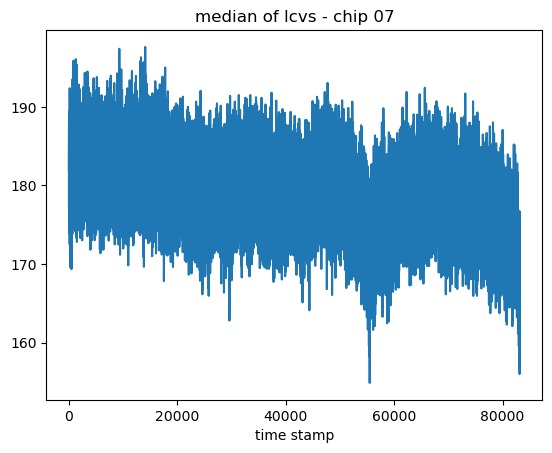

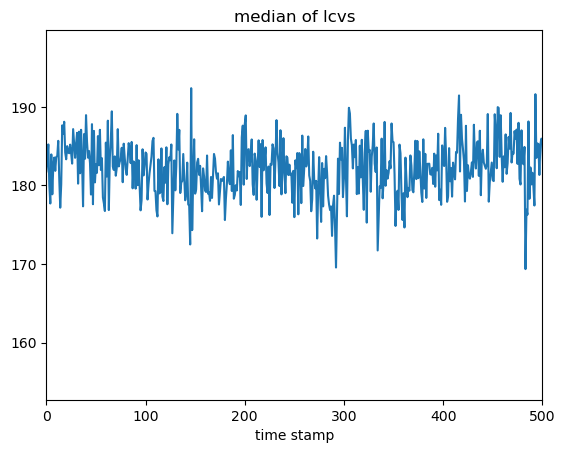

In [69]:
data_matrix = all_lcs_c07_shortened
plt.plot(np.median(data_matrix, axis=0))
plt.title("median of lcvs - chip 07")
plt.xlabel("time stamp")
plt.show()

plt.plot(np.median(data_matrix, axis=0))
plt.xlim(0,500)
plt.title("median of lcvs")
plt.xlabel("time stamp");

NOTE: the low frequency components look coherent, the high frequency components look stochastic

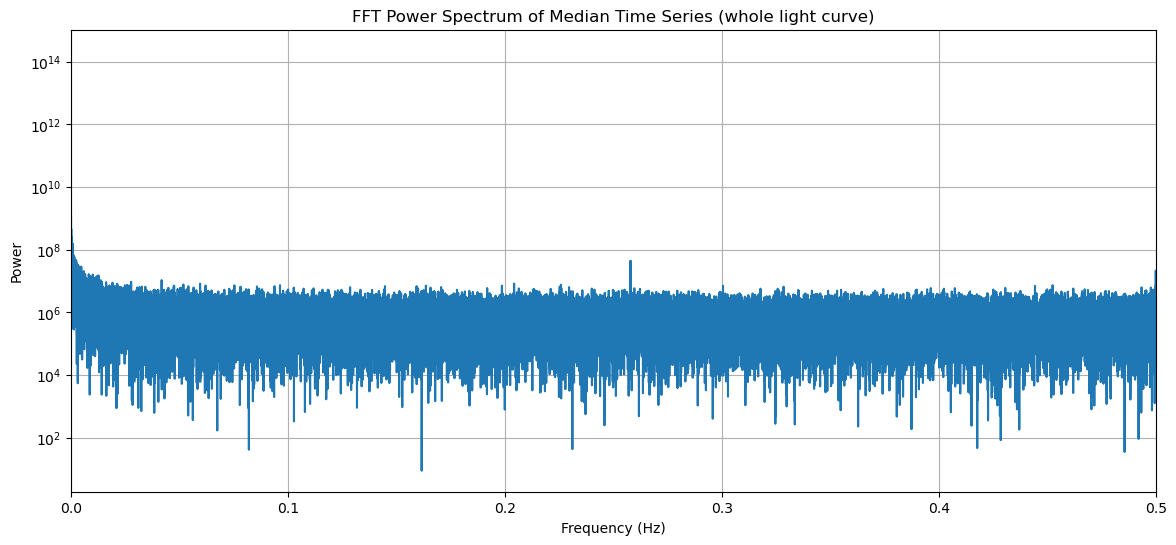

In [70]:
#median FFT

n = data_matrix.shape[1]
fft_vals = fft(np.median(data_matrix, axis=0))
freqs = fftfreq(n, d=1)

# Take only positive frequencies (up to Nyquist)
positive_freqs = freqs[:n//2]
positive_fft = fft_vals[:n//2]

# Power spectrum (magnitude squared)
power = np.abs(positive_fft)**2

plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series (whole light curve)')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()

there is one high frequency at 0.25Hz (1/timestamp) but ignore for now

# 3. low pass filter in fourier space

test different frequencies: what is the frequency at which lcvs become significantly less correlated?

In [44]:
def apply_fft_lowpass(data, fs=1, fc=0.003):
    """
    data: 1D numpy array (single sensor)
    fs: sampling frequency
    fc: cutoff frequency
    """
    n = len(data)
    fft_vals = fft(data)
    freqs = fftfreq(n, d=1)
    
    # Create a mask: keep frequencies where |freq| <= fc
    mask = np.abs(freqs) <= fc
    
    # Apply mask (zero out high frequencies)
    fft_vals_filtered = fft_vals * mask
    
    # Transform back to time domain (real part)
    return np.real(ifft(fft_vals_filtered))


In [57]:
data_matrix.T.shape

(86240, 219)

In [73]:
fc =  0.0003
df_lowpass = pd.DataFrame(
        [apply_fft_lowpass(data_matrix.T[:, i], 1, fc) for i in range(data_matrix.T.shape[1])]
    )
df_highpass = all_lcs_c07_shortened - df_lowpass


In [74]:
df_highpass

,0,1,2,3,4,5,6,7,8,9,...,83150,83151,83152,83153,83154,83155,83156,83157,83158,83159
0,-0.169758,3.401493,18.865166,6.443843,13.736094,-9.835884,3.556978,9.160532,15.600112,10.096941,...,12.049559,-16.238204,-8.155487,-35.089206,-7.572869,-13.520646,-31.658124,-22.285731,3.807485,-15.980711
1,5.732122,-12.791431,-0.693236,30.423649,-4.632762,1.680544,-3.734834,9.298485,14.262436,-4.417186,...,-12.722287,1.740281,3.995418,6.649846,-3.708226,8.745896,-14.831922,1.391955,-9.336105,4.636959
2,4.052434,-25.212908,15.897230,-20.238643,-24.504224,-2.866889,-20.070291,-1.844793,17.134131,3.966363,...,-33.313067,-34.621645,3.073659,-5.560040,-31.004660,-19.768030,-25.999166,-23.940576,-6.107718,19.550434
3,-0.958268,2.008387,8.669388,-7.627334,19.912791,-2.266207,3.750454,35.815525,-0.826120,11.370897,...,-3.061877,-3.174693,-8.151330,-8.113187,-10.497443,-5.502143,5.104236,10.071403,-4.881328,0.805158
4,2.017189,14.969746,26.297720,26.296857,19.895349,9.807246,2.363267,8.004178,6.009246,9.547567,...,-11.029091,-2.432509,-5.889527,-10.206724,-17.155767,-12.687462,2.539316,-24.416258,-2.669084,-12.264968
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,2.046602,-19.364210,-13.875327,-13.813867,-18.689718,-4.150432,3.624701,4.708891,10.257657,10.585666,...,-38.509939,-37.347358,-47.627825,-28.236288,-48.306660,-30.361766,-39.308529,-58.039282,-51.776316,-21.625007
215,-8.415883,-10.285164,0.120763,-1.867503,18.398993,7.458612,13.954328,13.187839,3.979854,13.003147,...,-6.493681,-17.010575,-19.725084,-25.708452,-11.086868,-32.036648,-37.485283,-27.115434,-14.761514,-24.473053
216,11.086135,17.757987,19.478574,-2.598585,2.224295,-6.311272,-5.644050,7.364082,11.037190,-1.405791,...,-28.918717,0.902136,-13.719472,1.204513,1.573030,19.849153,9.392305,-2.035539,-4.275578,-9.860025
217,40.695854,67.844708,67.993913,106.229408,69.090131,46.444981,52.078747,42.953587,32.469403,60.762305,...,4.264346,-20.410013,-29.298742,-28.410510,-14.511062,-50.022396,-79.593682,-83.873234,-121.450654,-129.923108


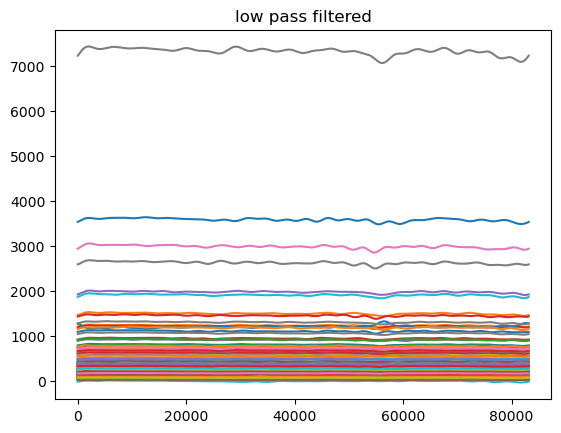

In [75]:
df_lowpass.T.plot(legend=None)
plt.title("low pass filtered");

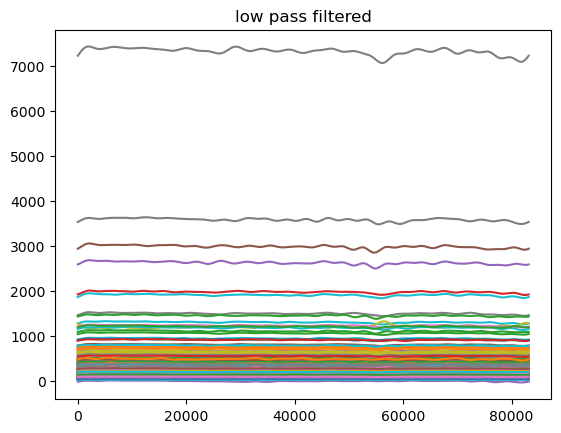

In [223]:
df_lowpass.plot(legend=None)
plt.title("low pass filtered");

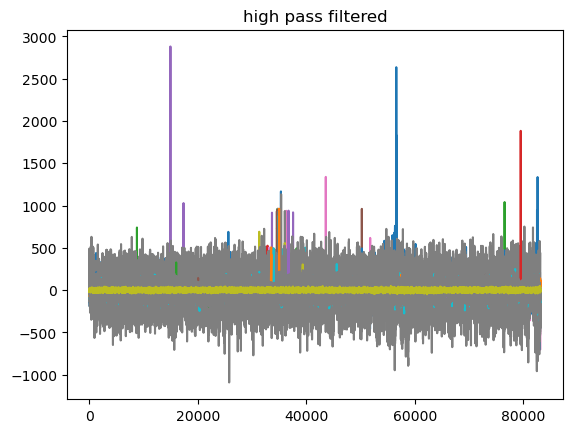

In [76]:
df_highpass.T.plot(legend=None)
plt.title("high pass filtered");

## scaling - just recenter the lightcurves before PCA (we scale to visualize but do not use scaled lcvs)

In [82]:
X = df_lowpass.values.T
X_centered = X - np.mean(X, axis=0)
Xdo = X_centered

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_centered)
#IF YOU WANT TO SCALE
#Xdo = X_scaled

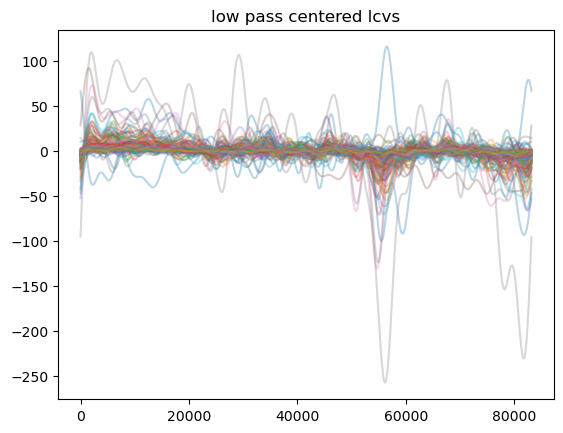

In [83]:
plt.plot(X_centered, alpha=0.3);
plt.title("low pass centered lcvs");

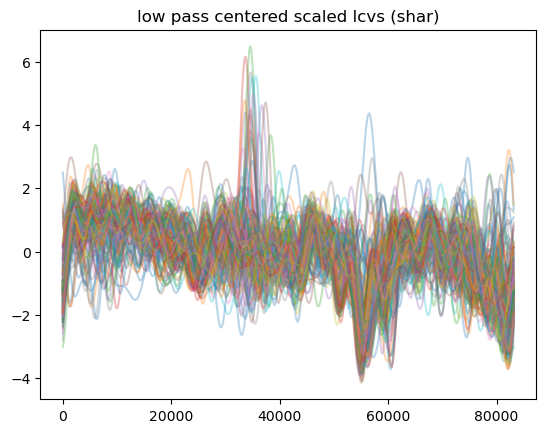

In [91]:
plt.plot(X_scaled, alpha=0.3);
plt.title("low pass centered scaled lcvs (shar)");

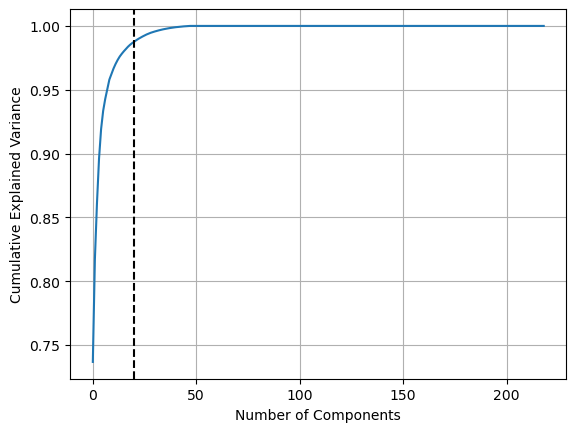

In [85]:
pca = PCA()
pca.fit(Xdo)

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.axvline(20, c="k", ls="--")
plt.grid(True)
plt.show()


with 10 components we are already above 95% variance. Use 20

# 4. run PCA decomposition

Text(0.5, 1.0, 'common noise (shar)')

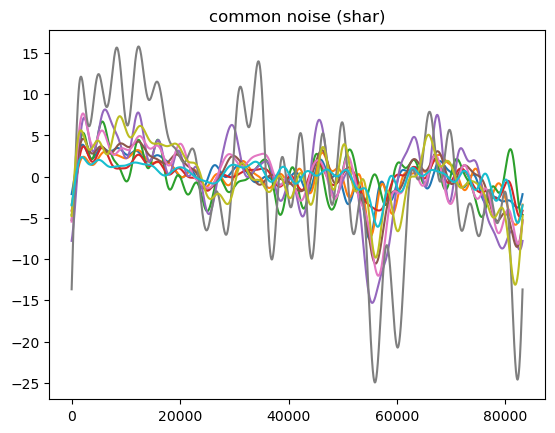

In [89]:
k = 10
pca_noise = PCA(n_components=k)
pca_noise.fit(Xdo)
# the common noise is the 20-components reconstructions of the lowpass data
common_noise = pca_noise.inverse_transform(pca_noise.transform(Xdo))
for i in range(k):
    plt.plot(common_noise[:,i]);
plt.title("common noise (shar)")

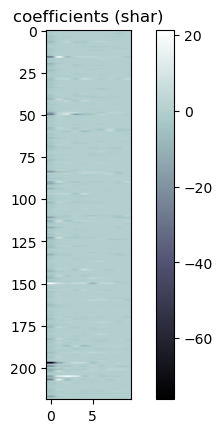

In [90]:
loadings = pca_noise.components_.T * np.sqrt(pca_noise.explained_variance_)
plt.imshow(loadings, aspect=0.2, cmap='bone')
plt.colorbar()

plt.title("coefficients (shar)");

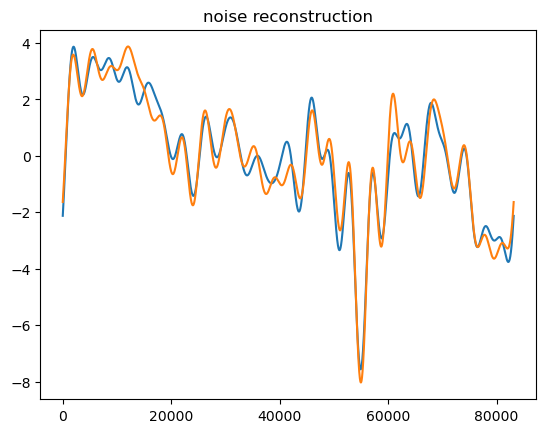

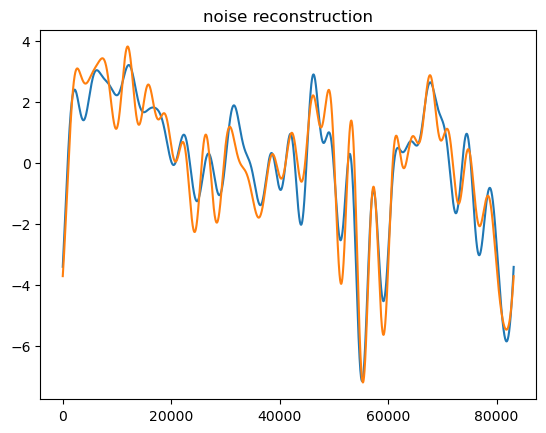

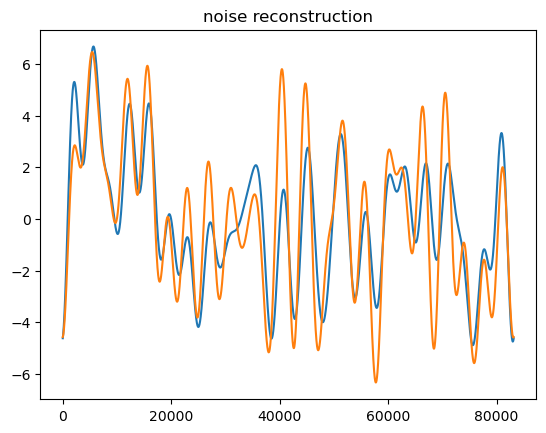

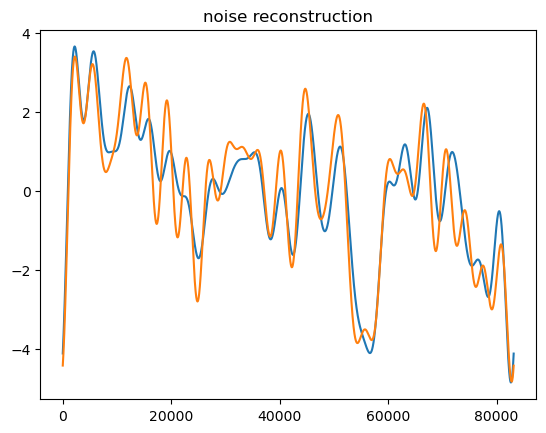

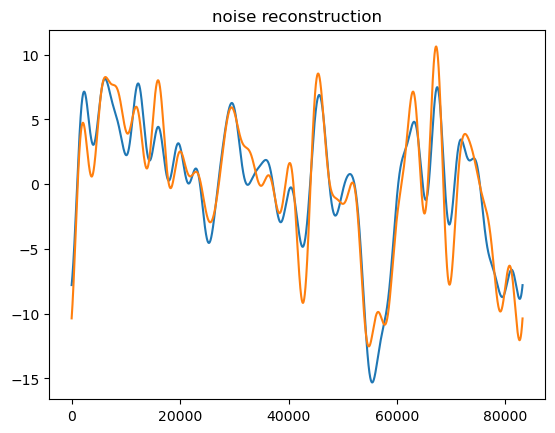

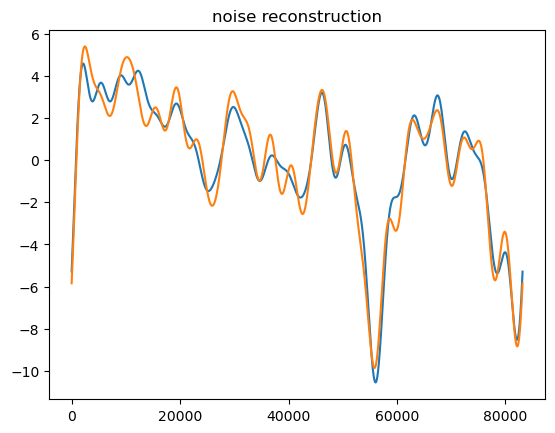

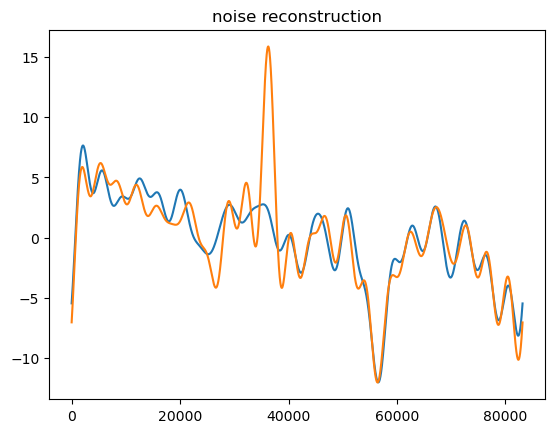

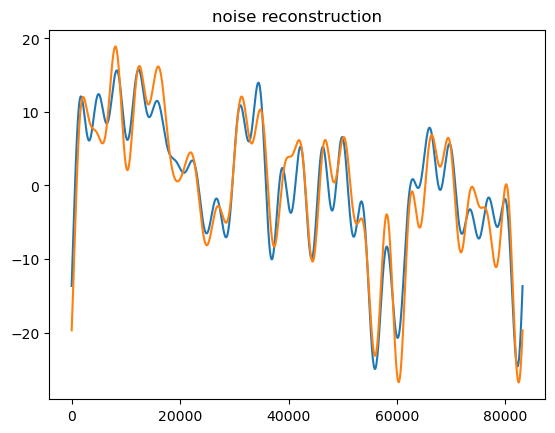

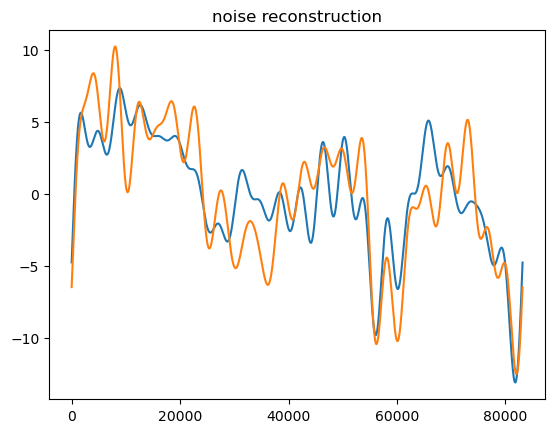

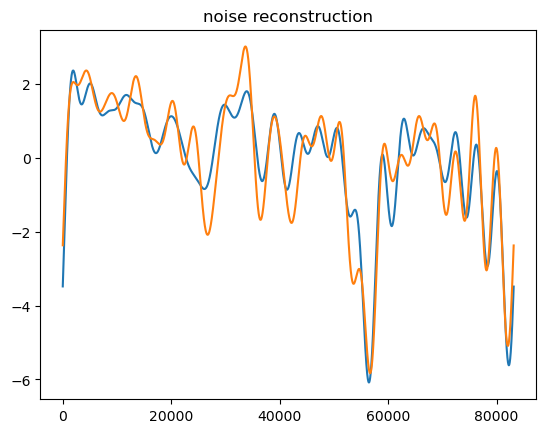

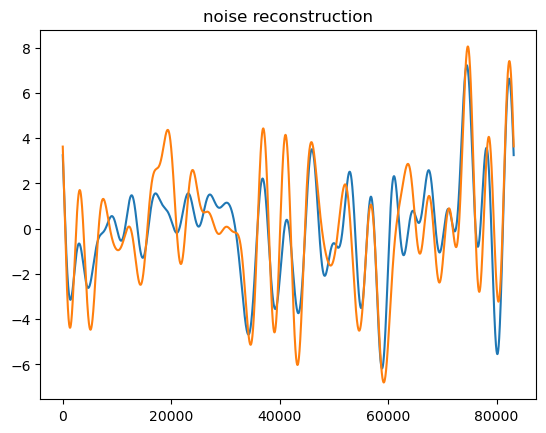

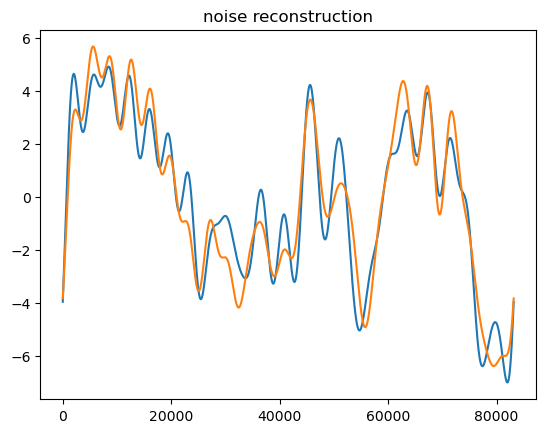

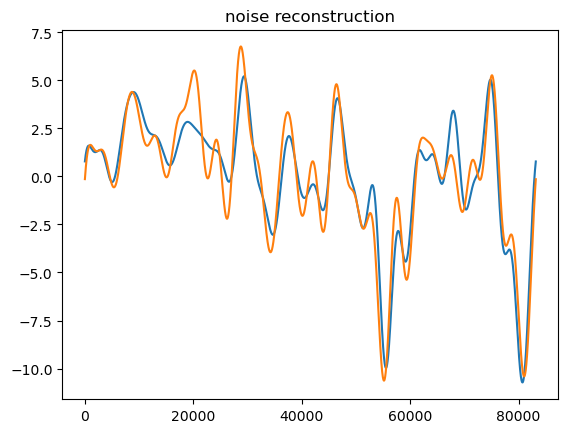

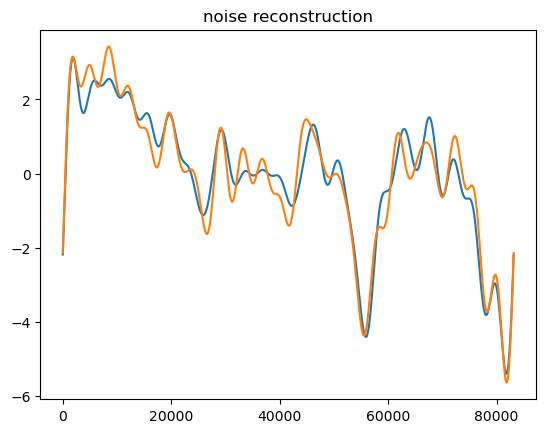

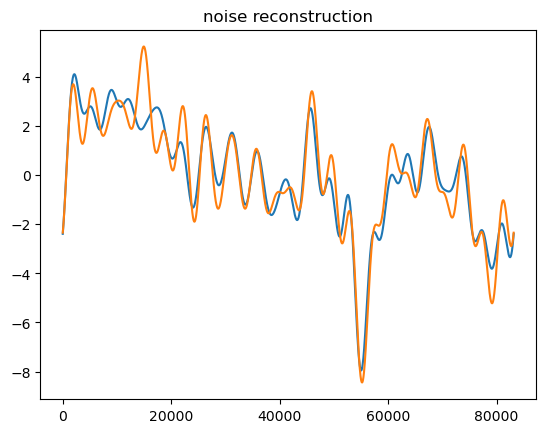

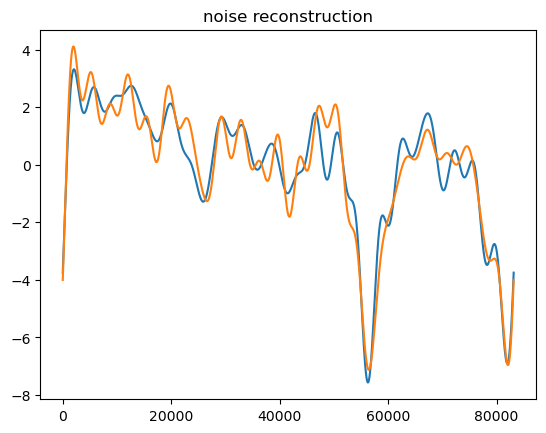

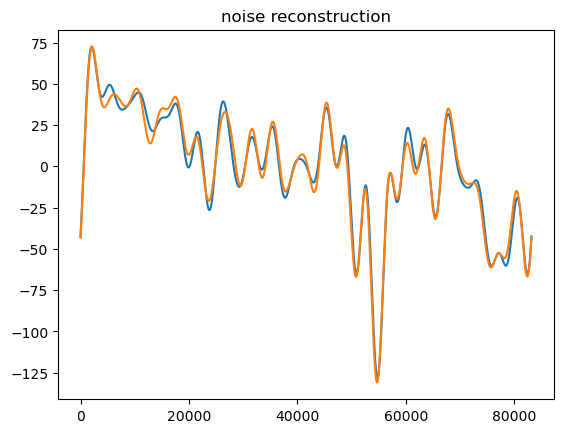

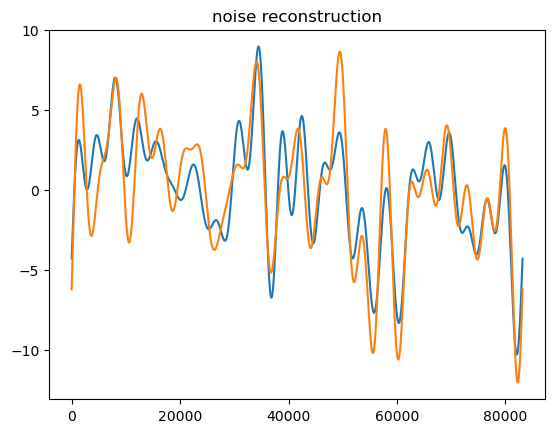

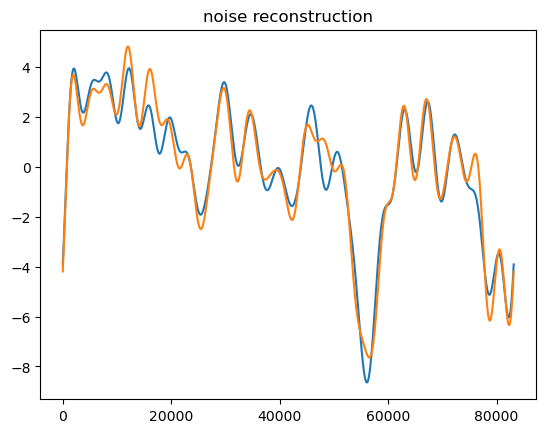

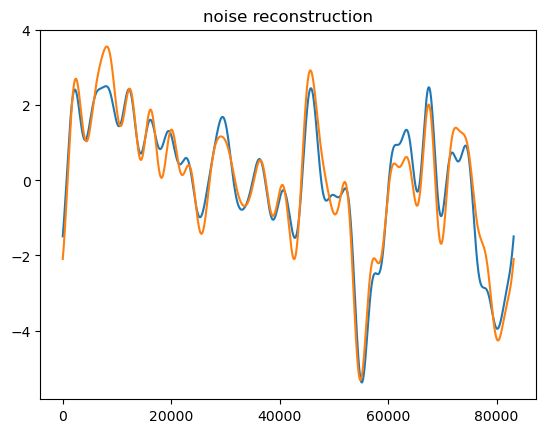

In [88]:
for i in range(20):
    plt.plot(common_noise[:,i], label="reconstructed (noise)")
    plt.plot(Xdo[:,i], label="lowpass original");
    plt.title("noise reconstruction")
    plt.show()
    

# 5. Generate denoised data as original - common noise

In [93]:
#denoised is the original minus the common low-frequency noise
X_denoised = data_matrix.T - common_noise


## check how it looks

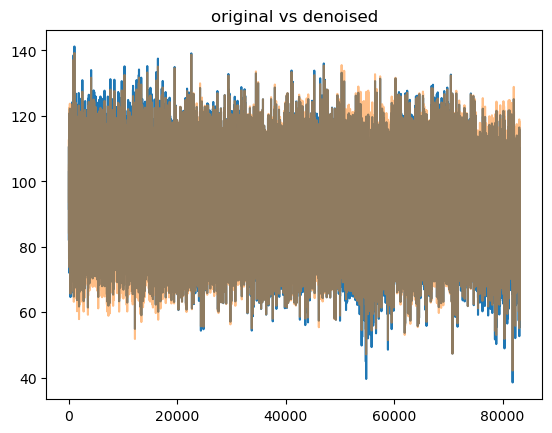

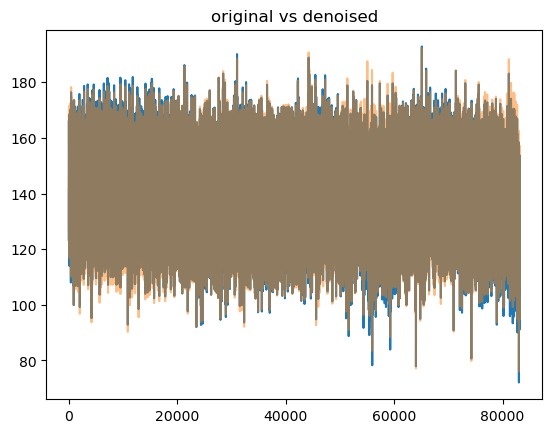

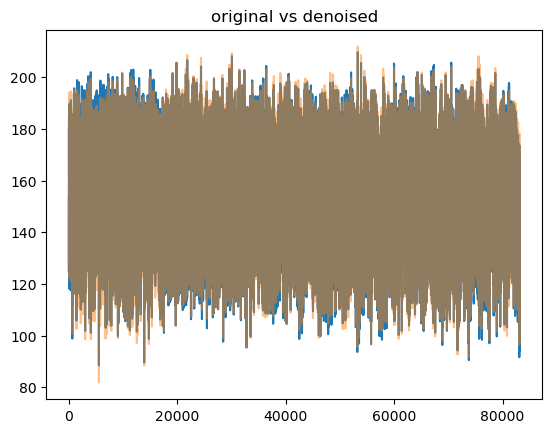

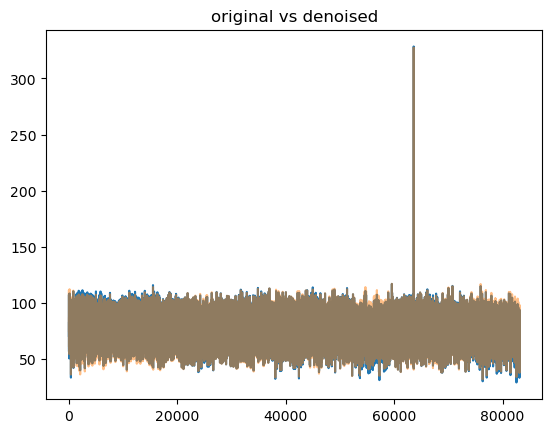

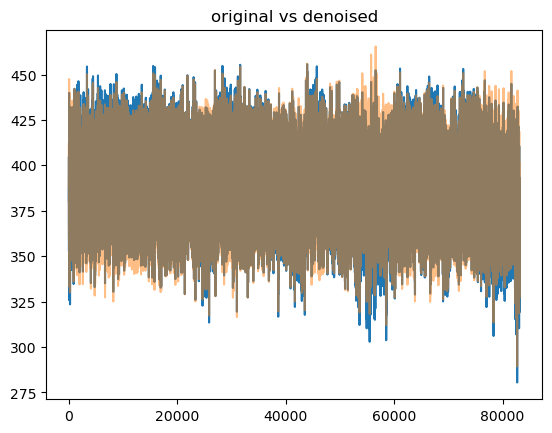

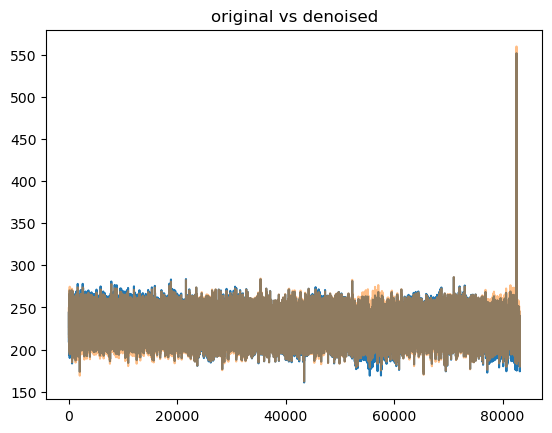

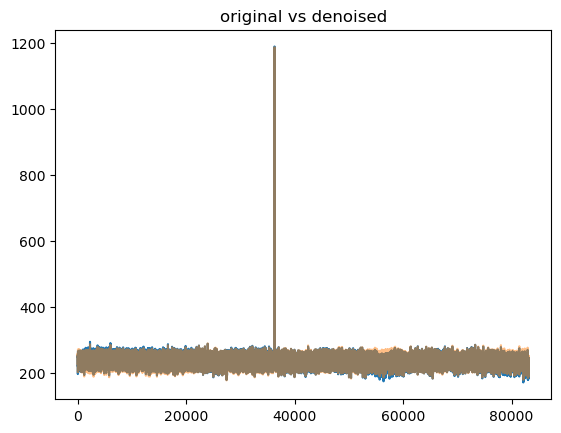

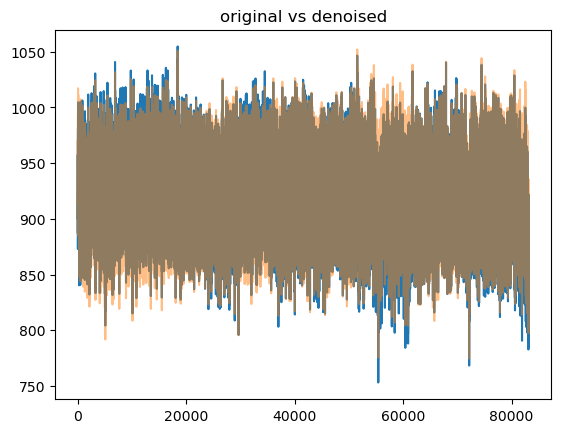

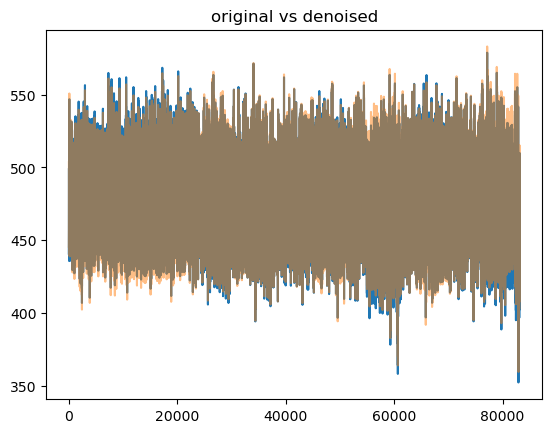

KeyboardInterrupt: 

In [95]:
for i,l in enumerate(data_matrix):
    if i>20: break
    plt.plot(l);
    plt.plot(X_denoised[:,i], alpha=0.5);
    plt.title("original vs denoised")
    plt.show()
    

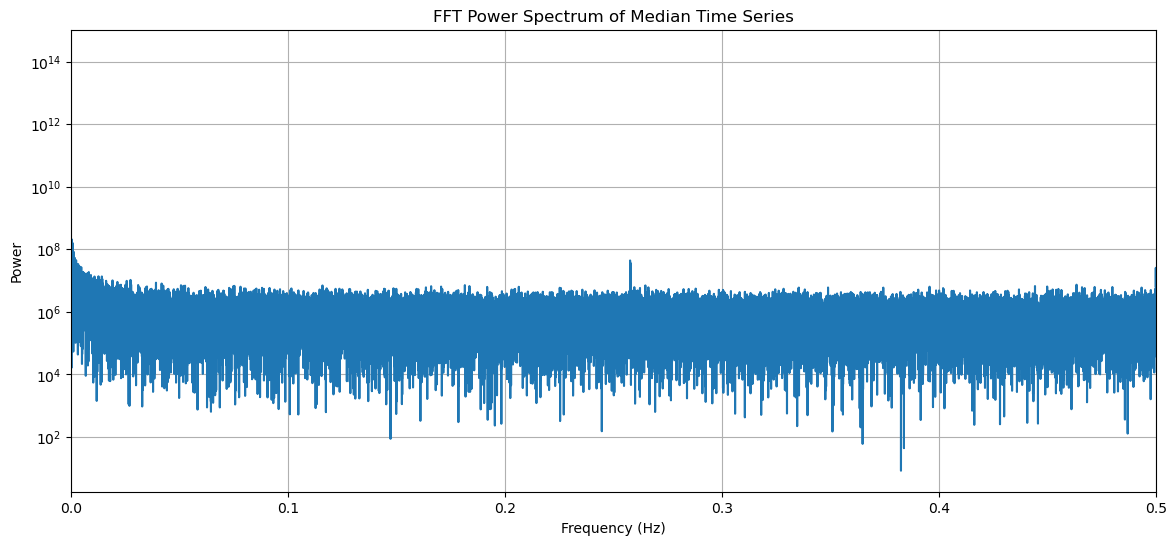

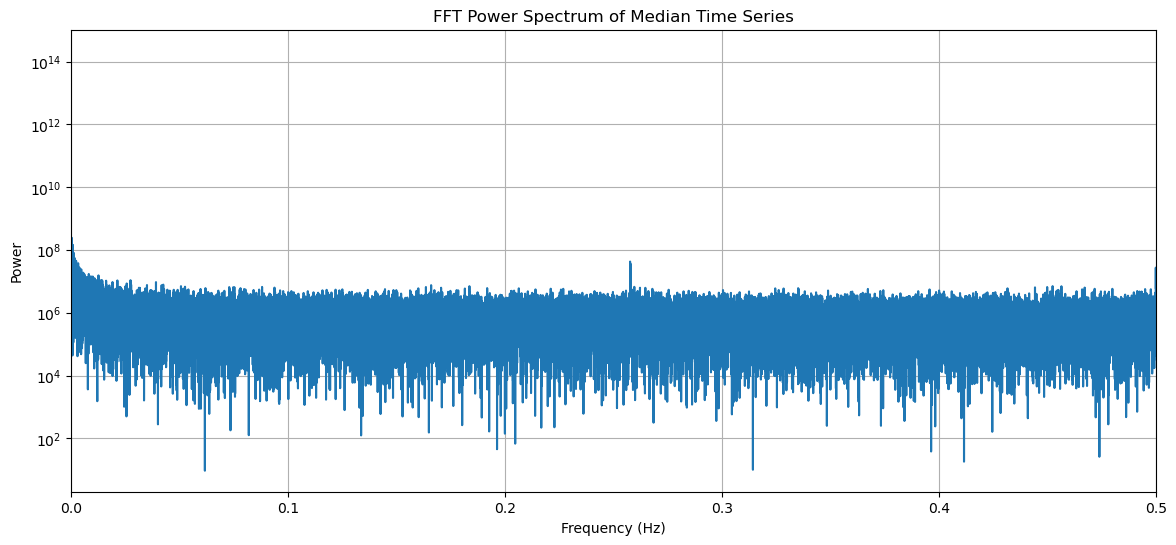

In [234]:
#median FFT

plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()


fft_vals = fft(np.median(X_denoised, axis=1))
freqs = fftfreq(n, d=1)

# Take only positive frequencies (up to Nyquist)
positive_freqs = freqs[:n//2]
positive_fft = fft_vals[:n//2]

# Power spectrum (magnitude squared)
power = np.abs(positive_fft)**2
plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()

spectrum does not change, noise is not periodic

Text(0.5, 1.0, 'originals')

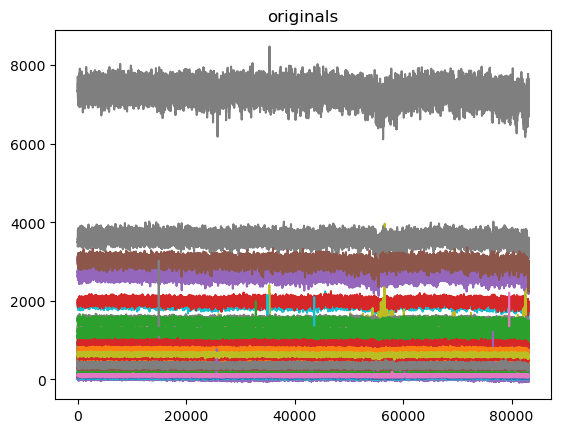

In [235]:
plt.plot(data_matrix);
plt.title("originals")

Text(0.5, 1.0, 'denoised')

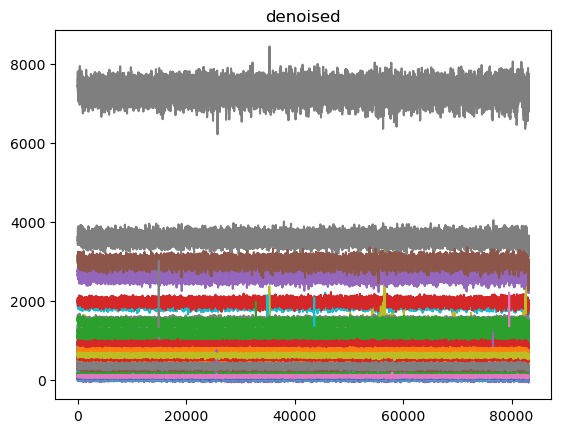

In [236]:
plt.plot(X_denoised);
plt.title("denoised")

(-15.0, 25.0)

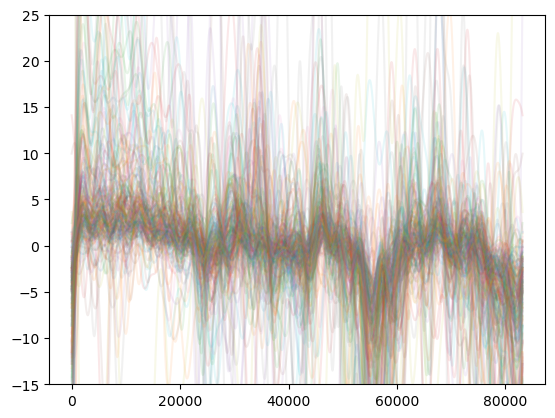

In [237]:
plt.plot(Xdo, alpha=0.1);
plt.ylim(-15,25)

X_denoised_centered = X_denoised - np.mean(X_denoised, axis=0)
plt.plot(X_denoised_centered, alpha=0.1);
plt.ylim(-15,25)

Text(0.5, 1.0, 'data median')

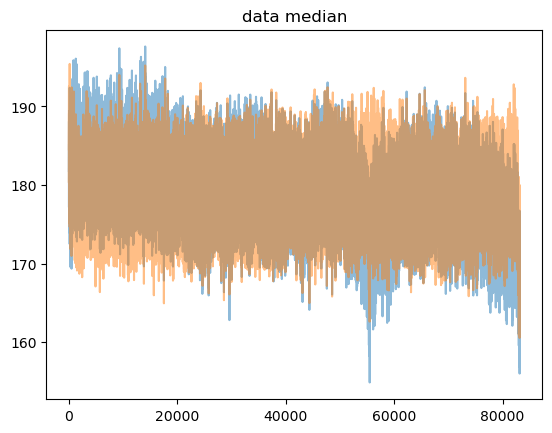

In [238]:
plt.plot(np.median(data_matrix, axis=1), alpha=0.5)
plt.plot(np.median(X_denoised, axis=1), alpha=0.5)
plt.title("data median")

data median looks stochastic

In [239]:
import numpy as np
from statsmodels.stats import diagnostic as diag


# Assume 'median_series' is your 1D array (83160 points)
# Test up to 10 lags (or 20, or 40)
lb_test = diag.acorr_ljungbox(np.median(data_matrix, axis=1), lags=[10,20,50,100,500,1000, 10000], return_df=True)
print(lb_test)

# Quick interpretation:
p_min = lb_test['lb_pvalue'].min()  # Look at the smallest p-value across lags
if p_min < 0.05:
    print(f"Strong structure detected (min p={p_min:.2e}). ")
else:
    print(f"Looks like pure white noise (p={p_min:.2e}).")


            lb_stat  lb_pvalue
10     1.791233e+05        0.0
20     3.402712e+05        0.0
50     7.636017e+05        0.0
100    1.392453e+06        0.0
500    5.518560e+06        0.0
1000   9.900244e+06        0.0
10000  3.762285e+07        0.0
Strong structure detected (min p=0.00e+00). 


In [240]:

# Assume 'median_series' is your 1D array (83160 points)
# Test up to 10 lags (or 20, or 40)
lb_test = diag.acorr_ljungbox(np.median(X_denoised, axis=1), lags=[10,20,50,100,500,1000, 10000], return_df=True)
print(lb_test)

# Quick interpretation:
p_max = lb_test['lb_pvalue'].max()  # Look at the smallest p-value across lags
if p_max < 0.05:
    print(f"Strong structure detected (min p={p_max:.10e}). ")
else:
    print(f"Looks like pure white noise (p={p_max:.10e}).")


             lb_stat  lb_pvalue
10      29648.576978        0.0
20      48619.667961        0.0
50      79652.479723        0.0
100    105074.917382        0.0
500    134927.140414        0.0
1000   142591.765773        0.0
10000  222224.414640        0.0
Strong structure detected (min p=0.0000000000e+00). 


there is still structure to a statistically significant level but decreased notably at all lags